# 探索式資料分析（EDA）

本 notebook 依照事先設計的 8 個問題進行分析。每個問題都先寫下**預期**，再看結果，最後寫**解讀**。

| # | 問題 | 對應的決策 |
| --- | --- | --- |
| Q1 | 分析母體的基本輪廓 | 母體 |
| Q2 | 活存餘額越高，轉化率越高嗎？ | 優先接觸誰 |
| Q3 | 收入越高，轉化率越高嗎？（含 Unknown） | 優先接觸誰 |
| Q4 | 控制餘額之後，收入還有影響嗎？ | 優先接觸誰 |
| Q5 | 近 6 個月有 App 點擊的客戶，轉化率比較高嗎？ | 優先接觸誰 |
| Q6 | KYC 等級越積極，轉化率越高嗎？ | 優先接觸誰 |
| Q7 | 瀏覽的理財標籤跟消費類別有關嗎？ | 推薦什麼 |
| Q8 | 閒置資金的分布能支撐多少月扣款？ | 推薦多少金額 |

> 本專案使用模擬資料，以下所有發現都是**模擬資料中的規律**，在真實情境下是否成立需要驗證（見計畫書 1.5）。

## 0. 環境設定與讀取資料

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import os, subprocess
import matplotlib.font_manager as fm

# 中文字型:Colab(Linux)沒有內建中文字型,找不到時自動安裝 Noto Sans CJK
CJK_FONT = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
if not any(f.name.startswith(("Microsoft JhengHei", "PingFang", "Heiti", "Noto Sans CJK")) for f in fm.fontManager.ttflist):
    if not os.path.exists(CJK_FONT):
        subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"], check=True)
    fm.fontManager.addfont(CJK_FONT)

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "PingFang TC", "Heiti TC", "Noto Sans CJK TC", "Noto Sans CJK JP", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

# 圖表顏色:主色一個、參考線一個,避免用顏色表達不存在的差異
MAIN = "#2a78d6"     # 主要長條
REF = "#52514e"      # 整體轉化率參考線
MUTED = "#a8a7a2"    # 次要資訊

pd.set_option("display.max_columns", None)

In [2]:
def path(name, folder):
    """Colab 直接上傳時檔案在根目錄;下載整個 repo 執行時在資料夾裡"""
    return name if os.path.exists(name) else os.path.join(folder, name)

client_profile = pd.read_csv(path("client_profile_cleaned.csv", "data_cleaned"))
deposit_balance = pd.read_csv(path("deposit_balance_cleaned.csv", "data_cleaned"), parse_dates=["month"])
card_transactions = pd.read_csv(path("card_transactions_cleaned.csv", "data_cleaned"), parse_dates=["transaction_month"])
app_engagement = pd.read_csv(path("app_engagement_cleaned.csv", "data_cleaned"), parse_dates=["month"])
conversion_label = pd.read_csv(path("conversion_label_cleaned.csv", "data_cleaned"))

for name, df in [("client_profile", client_profile), ("deposit_balance", deposit_balance),
                 ("card_transactions", card_transactions), ("app_engagement", app_engagement),
                 ("conversion_label", conversion_label)]:
    print(f"{name:20s} {df.shape}")

client_profile       (9000, 16)
deposit_balance      (108000, 3)
card_transactions    (191957, 5)
app_engagement       (49936, 4)
conversion_label     (9000, 3)


### 建立客戶層級的分析表

EDA 需要「一位客戶一列」的表。這裡只整理 EDA 會用到的欄位，正式的特徵工程在下一個階段另外設計。

- `avg_balance_12m`：2025/08–2026/07 的平均活存餘額
- `card_spend_monthly`：2026/03–2026/08 的每月平均刷卡金額（6 個月總額 ÷ 6）
- `has_app_click_6m`：近 6 個月是否有 App 理財點擊（`app_click_count_6m > 0`）

In [3]:
avg_balance = deposit_balance.groupby("customer_id")["checking_balance"].mean().rename("avg_balance_12m")
card_spend = (card_transactions.groupby("customer_id")["transaction_amount"].sum() / 6).rename("card_spend_monthly")

df = (client_profile
      .merge(conversion_label[["customer_id", "converted_to_sip"]], on="customer_id", how="left")
      .merge(avg_balance, on="customer_id", how="left")
      .merge(card_spend, on="customer_id", how="left"))
df["has_app_click_6m"] = df["app_click_count_6m"] > 0

# 檢查:每位客戶一列、合併後沒有缺值
assert df["customer_id"].is_unique
print("列數:", len(df))
print("合併後缺值:", df[["converted_to_sip", "avg_balance_12m", "card_spend_monthly"]].isna().sum().to_dict())

列數: 9000
合併後缺值: {'converted_to_sip': 0, 'avg_balance_12m': 0, 'card_spend_monthly': 0}


In [4]:
# 分析母體:未持有理財商品;對照組:已持有理財商品
target = df[~df["has_wealth_product"]].copy()
control = df[df["has_wealth_product"]].copy()
print("分析母體:", len(target), "人")
print("對照組(已理財):", len(control), "人")

分析母體: 7717 人
對照組(已理財): 1283 人


In [5]:
def conv_table(data, by, order=None):
    """依分組計算人數、轉化人數、轉化率與 95% 信賴區間(常態近似)"""
    t = data.groupby(by, observed=True)["converted_to_sip"].agg(人數="size", 轉化人數="sum")
    t["轉化率"] = t["轉化人數"] / t["人數"]
    t["誤差"] = 1.96 * np.sqrt(t["轉化率"] * (1 - t["轉化率"]) / t["人數"])
    if order is not None:
        t = t.reindex(order)
    return t

def plot_conv(t, title, xlabel, base_rate):
    """長條圖:各組轉化率 + 95% 信賴區間 + 整體轉化率參考線"""
    fig, ax = plt.subplots(figsize=(7.5, 4))
    x = np.arange(len(t))
    ax.bar(x, t["轉化率"], color=MAIN, width=0.6, yerr=t["誤差"], ecolor=MUTED, capsize=4)
    ax.axhline(base_rate, color=REF, linestyle="--", linewidth=1)
    ax.text(1.01, base_rate, f"整體 {base_rate:.1%}", transform=ax.get_yaxis_transform(), va="center", ha="left", color=REF, fontsize=9)
    for i, (rate, n) in enumerate(zip(t["轉化率"], t["人數"])):
        ax.text(i, rate + t["誤差"].iloc[i] + 0.003, f"{rate:.1%}\n(n={n:,})", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x, t.index.astype(str))
    ax.yaxis.set_major_locator(mtick.MaxNLocator(steps=[1, 2, 5, 10]))   # 刻度落在整數百分比,避免 2.5% 被顯示成 2%
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_ylim(0, (t["轉化率"] + t["誤差"]).max() * 1.35)
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("轉化率")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

## Q1. 分析母體的基本輪廓

- **我的預期**：7,717 人、轉化率約 6–7%、KYC 三組比例接近、餘額右偏。
- **後續影響**：整體轉化率是所有比較的基準線；類別不平衡 → 分層抽樣、看 PR-AUC；餘額右偏 → 用中位數與四分位數、建模時考慮取 log；保守型比例決定多少客戶沒有衛星配置。

In [6]:
base_rate = target["converted_to_sip"].mean()
summary = pd.DataFrame({
    "分析母體": [len(target), target["converted_to_sip"].mean(),
             target["avg_balance_12m"].median(), target["card_spend_monthly"].median(),
             target["income_annual_wan"].median(), target["has_app_click_6m"].mean()],
    "對照組(已理財)": [len(control), control["converted_to_sip"].mean(),
                 control["avg_balance_12m"].median(), control["card_spend_monthly"].median(),
                 control["income_annual_wan"].median(), control["has_app_click_6m"].mean()],
}, index=["人數", "轉化率", "平均活存餘額(中位數)", "每月刷卡(中位數)", "年收入(萬,中位數)", "近6個月有App點擊比例"])
summary.style.format({"分析母體": "{:,.3f}", "對照組(已理財)": "{:,.3f}"})

,分析母體,對照組(已理財)
人數,"7,717.000","1,283.000"
轉化率,0.067,0.047
平均活存餘額(中位數),"51,050.583","51,544.750"
每月刷卡(中位數),"10,946.075","11,567.333"
"年收入(萬,中位數)",49.468,49.468
近6個月有App點擊比例,0.301,0.297


In [7]:
# KYC 分布
kyc_order = ["保守型", "穩健型", "積極型"]
kyc_dist = target["kyc_risk_rating"].value_counts().reindex(kyc_order)
pd.DataFrame({"人數": kyc_dist, "比例": (kyc_dist / len(target)).round(3)})

,人數,比例
kyc_risk_rating,,
保守型,2879,0.373
穩健型,2822,0.366
積極型,2016,0.261


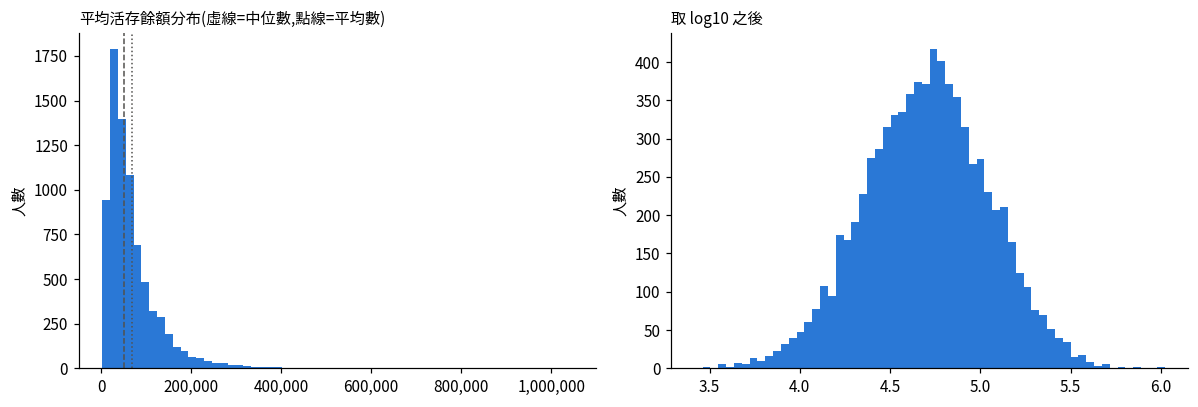

偏態係數(原始): 3.62 | 取 log 後: -0.07


In [8]:
# 活存餘額分布:原始尺度 vs 取 log 後
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(target["avg_balance_12m"], bins=60, color=MAIN)
axes[0].axvline(target["avg_balance_12m"].median(), color=REF, linestyle="--", linewidth=1)
axes[0].axvline(target["avg_balance_12m"].mean(), color=REF, linestyle=":", linewidth=1)
axes[0].set_title("平均活存餘額分布(虛線=中位數,點線=平均數)", loc="left", fontsize=10)
axes[0].xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
axes[1].hist(np.log10(target["avg_balance_12m"]), bins=60, color=MAIN)
axes[1].set_title("取 log10 之後", loc="left", fontsize=10)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylabel("人數")
plt.tight_layout()
plt.show()
print("偏態係數(原始):", round(target["avg_balance_12m"].skew(), 2), "| 取 log 後:", round(np.log10(target["avg_balance_12m"]).skew(), 2))

在模擬資料中，分析母體 7,717 人，轉化率 6.7%；

分析母體跟對照組的轉化率有明顯差距（6.7% vs 4.7%），
其餘特徵無明顯差距，

餘額分布右偏。

符合預期結果!



## Q2. 活存餘額越高，轉化率越高嗎？

- **我的預期**：是。
- **後續影響**：如果差距明顯，餘額是模型的重要特徵，也是名單篩選的依據；如果沒差，「閒置資金」這個假設就要打問號。

,人數,轉化人數,轉化率,誤差
balance_q,,,,
Q1(最低25%),1930,55,2.8%,±0.7%
Q2,1929,82,4.3%,±0.9%
Q3,1929,138,7.2%,±1.2%
Q4(最高25%),1929,245,12.7%,±1.5%


各組餘額範圍:
               min        max
balance_q                    
Q1(最低25%)   2620.0    29369.0
Q2         29387.0    51051.0
Q3         51058.0    85911.0
Q4(最高25%)  85922.0  1045968.0


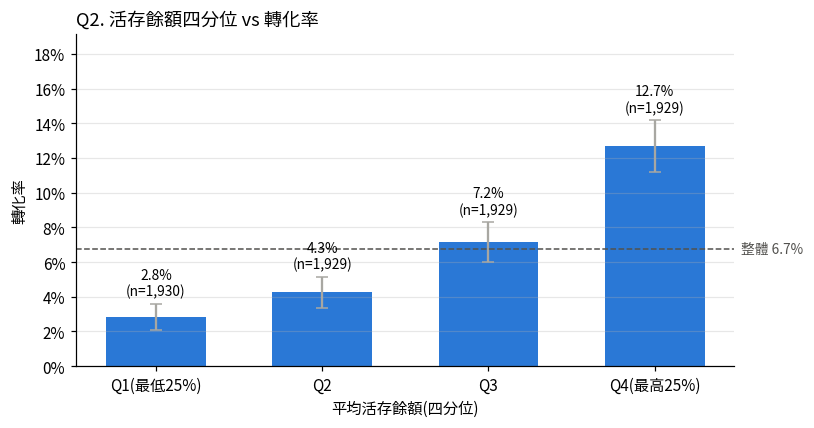

最高 vs 最低四分位轉化率倍數: 4.46 倍


In [9]:
target["balance_q"] = pd.qcut(target["avg_balance_12m"], 4, labels=["Q1(最低25%)", "Q2", "Q3", "Q4(最高25%)"])
t2 = conv_table(target, "balance_q")
display(t2.style.format({"轉化率": "{:.1%}", "誤差": "±{:.1%}"}))
print("各組餘額範圍:")
print(target.groupby("balance_q", observed=True)["avg_balance_12m"].agg(["min", "max"]).round(0))
plot_conv(t2, "Q2. 活存餘額四分位 vs 轉化率", "平均活存餘額(四分位)", base_rate)
print(f"最高 vs 最低四分位轉化率倍數: {t2['轉化率'].iloc[-1] / t2['轉化率'].iloc[0]:.2f} 倍")

在模擬資料中，活存餘額越高，轉化率越高(2.8% → 4.3% → 7.2% → 12.7%)。

最高組是最低組的 4.5 倍，而且四組逐步上升。

符合預期結果，且差距比預期明顯!

## Q3. 收入越高，轉化率越高嗎？（含 Unknown 組）

- **我的預期**：是。
- **後續影響**：如果收入越高轉化率越高，收入可能是模型的重要特徵（要再用 Q4 確認）；如果沒有，就代表無法以收入判斷客戶價值。
- **注意**：Unknown 是客戶不揭露收入，單獨成一組，不和其他組合併。

,人數,轉化人數,轉化率,誤差
income_tier,,,,
<40萬,2690,143,5.3%,±0.8%
40-60萬,1313,90,6.9%,±1.4%
60-80萬,1087,74,6.8%,±1.5%
80-120萬,1195,94,7.9%,±1.5%
120萬+,561,63,11.2%,±2.6%
Unknown,871,56,6.4%,±1.6%


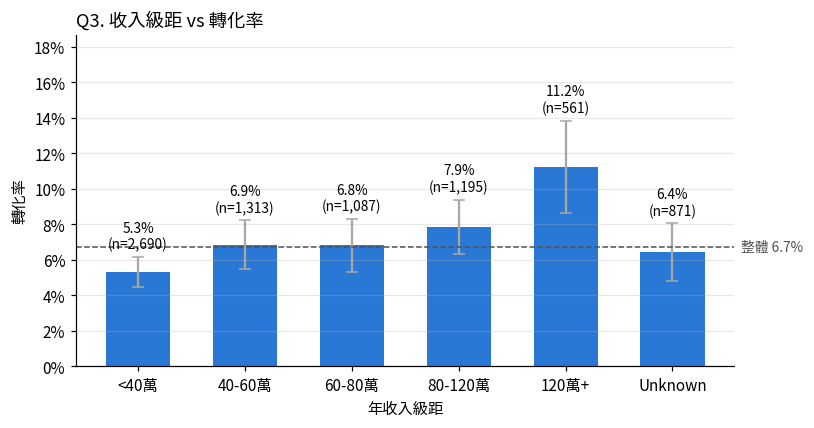

In [10]:
income_order = ["<40萬", "40-60萬", "60-80萬", "80-120萬", "120萬+", "Unknown"]
t3 = conv_table(target, "income_tier", order=income_order)
display(t3.style.format({"轉化率": "{:.1%}", "誤差": "±{:.1%}"}))
plot_conv(t3, "Q3. 收入級距 vs 轉化率", "年收入級距", base_rate)

在模擬資料中，最高與最低收入組差了2倍，但中間三組幾乎相同。

Unknown 組 6.4%，跟整體差不多。

部分符合預期結果!需要在Q4確認是否為餘額造成!

## Q4. 控制餘額之後，收入還有影響嗎？

- **我的預期**：活存餘額的影響比收入大。
- **讀法**：
    - **同一列內左右比**（餘額相近、收入不同）→ 收入有沒有**獨立**影響
    - **同一欄內上下比**（收入相同、餘額不同）→ 餘額有沒有**獨立**影響
- **後續影響**：如果同一列內各格差不多 → 收入沒有獨立效果，模型可以不放收入，結論也不能寫「應優先接觸高收入客戶」；如果同一列內仍有明顯差異 → 兩個都放進模型和名單篩選。
- **注意**：每格人數較少，信賴區間較寬，看**整體趨勢**，不要過度解讀單一格子。

收入與餘額的相關係數(Spearman): 0.439


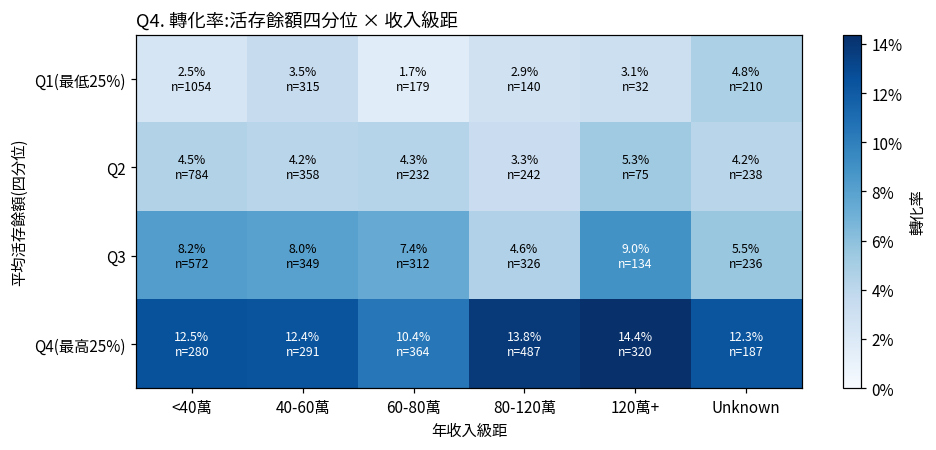

In [11]:
print("收入與餘額的相關係數(Spearman):",
      round(target.loc[target["income_tier"] != "Unknown", ["income_annual_wan", "avg_balance_12m"]].corr(method="spearman").iloc[0, 1], 3))

pivot_rate = target.pivot_table(index="balance_q", columns="income_tier", values="converted_to_sip",
                                aggfunc="mean", observed=True).reindex(columns=income_order)
pivot_n = target.pivot_table(index="balance_q", columns="income_tier", values="converted_to_sip",
                             aggfunc="size", observed=True).reindex(columns=income_order)

fig, ax = plt.subplots(figsize=(9, 4.2))
im = ax.imshow(pivot_rate.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(len(income_order)), income_order)
ax.set_yticks(range(len(pivot_rate.index)), pivot_rate.index)
for i in range(pivot_rate.shape[0]):
    for j in range(pivot_rate.shape[1]):
        rate, n = pivot_rate.iat[i, j], pivot_n.iat[i, j]
        if pd.notna(rate):
            color = "white" if rate > np.nanmax(pivot_rate.values) * 0.6 else "black"
            ax.text(j, i, f"{rate:.1%}\nn={int(n)}", ha="center", va="center", fontsize=8, color=color)
ax.set_title("Q4. 轉化率:活存餘額四分位 × 收入級距", loc="left")
ax.set_xlabel("年收入級距")
ax.set_ylabel("平均活存餘額(四分位)")
fig.colorbar(im, ax=ax, format=mtick.PercentFormatter(1.0, decimals=0), label="轉化率")
plt.tight_layout()
plt.show()

In [12]:
# 輔助判讀:每一列(餘額相同)內,收入最高組與最低組的轉化率差距
row_check = pd.DataFrame({
    "<40萬": pivot_rate["<40萬"],
    "120萬+": pivot_rate["120萬+"],
})
row_check["差距(百分點)"] = (row_check["120萬+"] - row_check["<40萬"]) * 100
row_check.style.format({"<40萬": "{:.1%}", "120萬+": "{:.1%}", "差距(百分點)": "{:+.1f}"})

,<40萬,120萬+,差距(百分點)
balance_q,,,
Q1(最低25%),2.5%,3.1%,+0.7
Q2,4.5%,5.3%,+0.9
Q3,8.2%,9.0%,+0.7
Q4(最高25%),12.5%,14.4%,+1.9


在模擬資料中，年收入與餘額相關(Spearman:0.44)，

控制餘額後，收入沒有一致的獨立影響

符合預期結果。

## Q5. 近 6 個月有 App 點擊的客戶，轉化率比較高嗎？

- **我的預期**：是。
- **後續影響**：如果是，App 點擊是重要特徵；如果不是，模型就不放這個特徵，冷啟動客戶（沒有 App 紀錄的約 70%）也不需要降低接觸優先度。
- **分組方式**：**全部客戶**依「近 6 個月是否有 App 點擊」分兩組（`app_click_count_6m > 0`）。

,人數,轉化人數,轉化率,誤差
has_app_click_6m,,,,
沒有點擊(冷啟動),5397,296,5.5%,±0.6%
有點擊,2320,224,9.7%,±1.2%


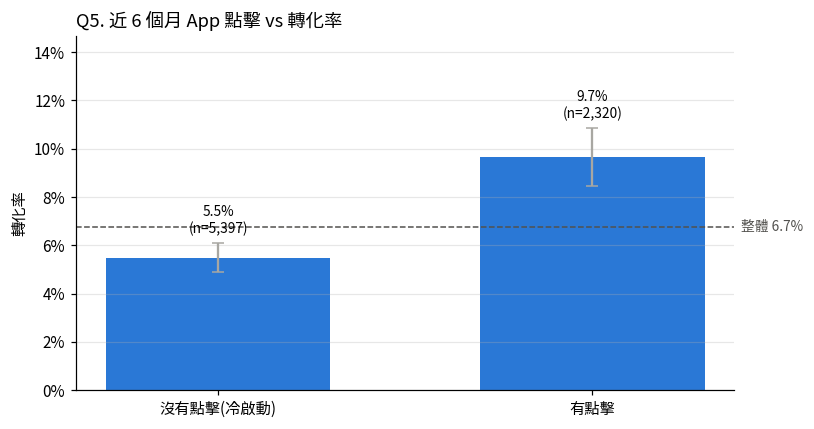

有點擊 / 沒有點擊 轉化率倍數: 1.76 倍


In [13]:
t5 = conv_table(target, target["has_app_click_6m"].map({True: "有點擊", False: "沒有點擊(冷啟動)"}),
                order=["沒有點擊(冷啟動)", "有點擊"])
display(t5.style.format({"轉化率": "{:.1%}", "誤差": "±{:.1%}"}))
plot_conv(t5, "Q5. 近 6 個月 App 點擊 vs 轉化率", "", base_rate)
print(f"有點擊 / 沒有點擊 轉化率倍數: {t5.loc['有點擊', '轉化率'] / t5.loc['沒有點擊(冷啟動)', '轉化率']:.2f} 倍")

在模擬資料中，有點擊紀錄的客戶，轉化率是沒有點擊紀錄的客戶的約1.8倍

(9.7% vs 5.5%)!

符合預期結果!

## Q6. KYC 等級越積極，轉化率越高嗎？

- **我的預期**：是，越積極代表越能承擔風險。
- **後續影響**：如果是，KYC 也可以作為名單排序的重要特徵；如果不是，KYC 只作為內容過濾的合規硬規則。

,人數,轉化人數,轉化率,誤差
kyc_risk_rating,,,,
保守型,2879,163,5.7%,±0.8%
穩健型,2822,189,6.7%,±0.9%
積極型,2016,168,8.3%,±1.2%


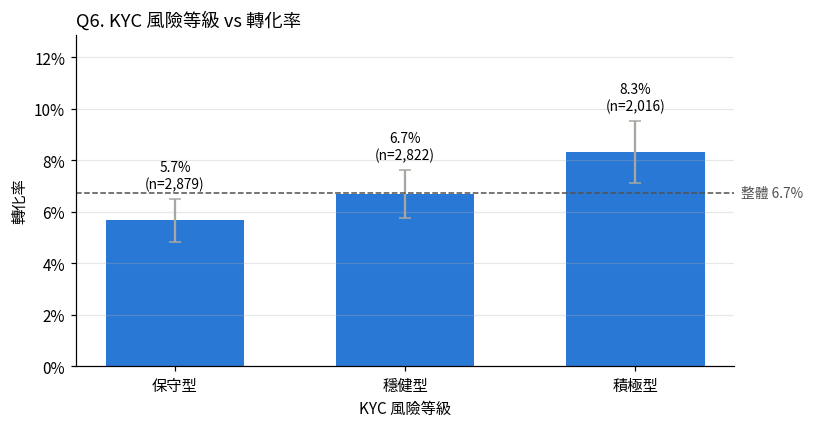

In [14]:
t6 = conv_table(target, "kyc_risk_rating", order=kyc_order)
display(t6.style.format({"轉化率": "{:.1%}", "誤差": "±{:.1%}"}))
plot_conv(t6, "Q6. KYC 風險等級 vs 轉化率", "KYC 風險等級", base_rate)

在模擬資料中，KYC等級越積極，轉化率越高(5.7% → 6.7% → 8.3%)!

符合預期結果!

## Q7. 瀏覽的理財標籤跟消費類別有關嗎？

- **我的預期**：有，關聯性大。
- **後續影響**：如果有，代表消費行為能反映理財偏好，內容過濾可以用消費輪廓推薦主題；如果沒有，內容過濾的權重要重新設計，或改成依 KYC 推薦預設商品。
- **做法**：只看近 6 個月有 App 點擊的客戶。每位客戶取「刷卡金額最高的消費類別」和「點擊次數最多的理財標籤」，畫交叉表。每一列加總為 100%，比較不同消費類別的客戶，點擊標籤的分布有沒有不同。
- **比較基準**：如果消費類別和標籤無關，每一列的分布應該都跟最下面的「全體」差不多。

分析人數(有 App 點擊的分析母體): 2320


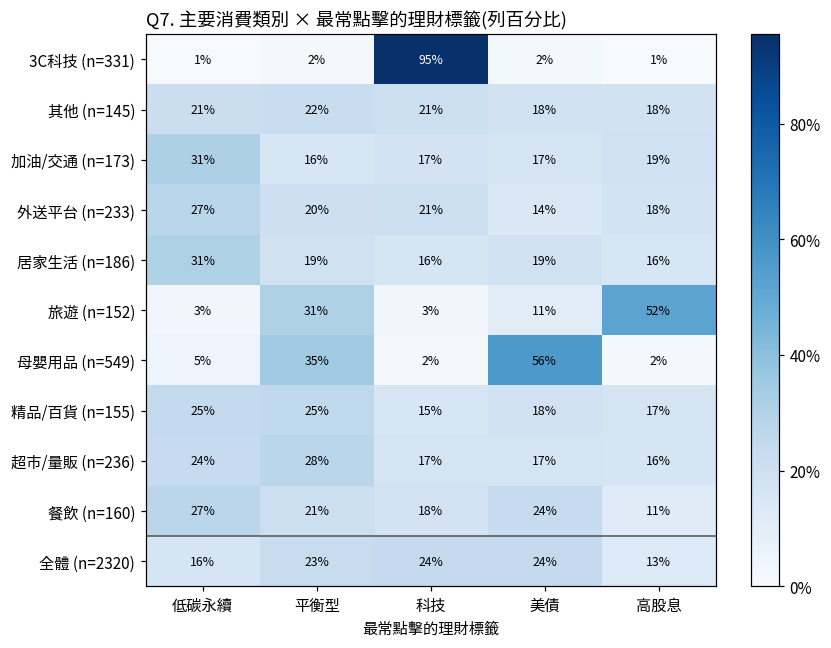

In [15]:
# 每位客戶的主要消費類別(6 個月刷卡金額最高)與最常點擊的標籤
dominant_mcc = (card_transactions.groupby(["customer_id", "mcc_category"])["transaction_amount"].sum()
                .groupby("customer_id").idxmax().str[1].rename("主要消費類別"))
top_tag = (app_engagement.groupby(["customer_id", "tag_clicked"])["click_count"].sum()
           .groupby("customer_id").idxmax().str[1].rename("最常點擊標籤"))

app_users = target[target["has_app_click_6m"]][["customer_id"]].merge(dominant_mcc, on="customer_id").merge(top_tag, on="customer_id")
print("分析人數(有 App 點擊的分析母體):", len(app_users))

ct = pd.crosstab(app_users["主要消費類別"], app_users["最常點擊標籤"], normalize="index")
ct.loc["全體"] = app_users["最常點擊標籤"].value_counts(normalize=True)
ct_n = app_users["主要消費類別"].value_counts()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(ct.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(ct.shape[1]), ct.columns)
ax.set_yticks(range(ct.shape[0]), [f"{i} (n={ct_n.get(i, len(app_users))})" for i in ct.index])
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        v = ct.iat[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > ct.values.max() * 0.6 else "black")
ax.axhline(ct.shape[0] - 1.5, color=REF, linewidth=1)
ax.set_title("Q7. 主要消費類別 × 最常點擊的理財標籤(列百分比)", loc="left")
ax.set_xlabel("最常點擊的理財標籤")
fig.colorbar(im, ax=ax, format=mtick.PercentFormatter(1.0, decimals=0))
plt.tight_layout()
plt.show()

In [16]:
# 統計檢定:卡方獨立性檢定(虛無假設:消費類別與點擊標籤無關)
from scipy.stats import chi2_contingency
observed = pd.crosstab(app_users["主要消費類別"], app_users["最常點擊標籤"])
chi2, p, dof, _ = chi2_contingency(observed)
cramers_v = np.sqrt(chi2 / (observed.values.sum() * (min(observed.shape) - 1)))
print(f"卡方 = {chi2:.1f}, 自由度 = {dof}, p 值 = {p:.2e}")
print(f"Cramér's V = {cramers_v:.3f}  (關聯強度:約 0.1 弱、0.3 中、0.5 強)")

卡方 = 1811.9, 自由度 = 36, p 值 = 0.00e+00
Cramér's V = 0.442  (關聯強度:約 0.1 弱、0.3 中、0.5 強)


在模擬資料中，
整體呈現中強關聯（卡方檢定 p < 0.001，Cramér's V = 0.44），


但關聯只集中在三類：

3C 科技 → 科技（95%）、
母嬰用品 → 美債（56%）與平衡型（35%）、

旅遊 → 高股息（52%）與平衡型（31%）；

其他 7 類的標籤分布較平均（各標籤約 15–30%）。

部分符合預期，只有三類有關聯!


## Q8. 閒置資金的分布能支撐多少月扣款？

- **規則**（見計畫書附錄 A）：
    - 可投資閒置資金 = 平均活存餘額 − 3 個月的刷卡支出（緊急預備金）
    - 建議月扣款（計算值）= 可投資閒置資金 ÷ 12
    - **可推薦客戶**：可投資閒置資金 ≥ 12,000 元（一年至少能扣最低門檻 1,000 元 × 12 個月），也就是計算值 ≥ 1,000
    - 建議月扣款：無條件捨去到千元，上限 10,000 元。一年的扣款不會超過可投資閒置資金，不會動用緊急預備金
    - **規則修正紀錄**：原本的規則是「1–999 拉到 1,000、四捨五入到千元」，會讓一年的扣款超過可投資閒置資金、動用緊急預備金，與上面的前提矛盾，已修正（見計畫書附錄 A、第 7 節）
- **我的預期**：

| 組別 | 建議月扣款（套上下限之前） | 預期 | 處理方式 |
| --- | --- | --- | --- |
| 不適合推薦 | 可投資資金 ≤ 0 | 10% | 不放進接觸名單 |
| 資金不足最低扣款 | 1 – 999 | 10% | 不推薦（閒置資金未滿 12,000 元） |
| 低扣款 | 1,000 – 2,999 | 20% | 依計算結果 |
| 一般 | 3,000 – 4,999 | 35% | 依計算結果 |
| 中高 | 5,000 – 9,999 | 15% | 依計算結果 |
| 高（達上限） | ≥ 10,000 | 10% | 截在 10,000 |

- **後續影響**：結果用來確認附錄 A 的推薦門檻與上限是否合理；如果大部分客戶都被拉到同一個金額，期望價值排序就會跟機率排序幾乎一樣，可以考慮改放「下一步」。
- **注意**：刷卡只是支出的一部分（沒有房租、貸款等），所以緊急預備金可能被低估。

In [17]:
EMERGENCY_MONTHS = 3
MIN_SIP, MAX_SIP = 1_000, 10_000

target["investable_idle"] = target["avg_balance_12m"] - EMERGENCY_MONTHS * target["card_spend_monthly"]
target["sip_raw"] = target["investable_idle"] / 12

bins = [-np.inf, 0, 999.999, 2_999.999, 4_999.999, 9_999.999, np.inf]
labels = ["不適合推薦(≤0)", "資金不足(1-999)", "低扣款(1,000-2,999)", "一般(3,000-4,999)", "中高(5,000-9,999)", "高(≥10,000)"]
target["sip_band"] = pd.cut(target["sip_raw"], bins=bins, labels=labels)

expected = pd.Series([0.10, 0.10, 0.20, 0.35, 0.15, 0.10], index=labels)
band = pd.DataFrame({
    "人數": target["sip_band"].value_counts().reindex(labels),
    "實際比例": target["sip_band"].value_counts(normalize=True).reindex(labels),
    "預期比例": expected,
})
band["差距(百分點)"] = (band["實際比例"] - band["預期比例"]) * 100
display(band.style.format({"實際比例": "{:.1%}", "預期比例": "{:.0%}", "差距(百分點)": "{:+.1f}"}))
print("建議月扣款(計算值)的四分位數:")
print(target["sip_raw"].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(0))

,人數,實際比例,預期比例,差距(百分點)
不適合推薦(≤0),1733,22.5%,10%,+12.5
資金不足(1-999),1229,15.9%,10%,+5.9
"低扣款(1,000-2,999)",2146,27.8%,20%,+7.8
"一般(3,000-4,999)",1059,13.7%,35%,-21.3
"中高(5,000-9,999)",1049,13.6%,15%,-1.4
"高(≥10,000)",501,6.5%,10%,-3.5


建議月扣款(計算值)的四分位數:
0.10   -1297.0
0.25     178.0
0.50    1674.0
0.75    4137.0
0.90    7973.0
Name: sip_raw, dtype: float64


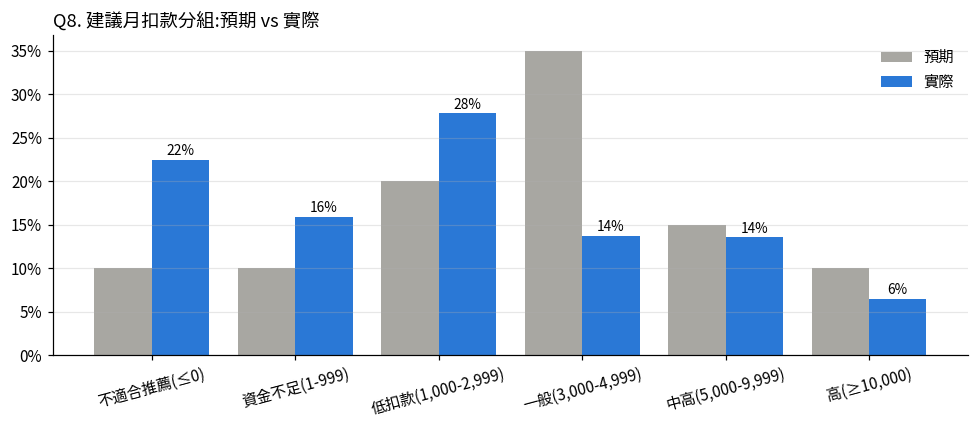

In [18]:
# 實際 vs 預期
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(labels))
ax.bar(x - 0.2, band["預期比例"], width=0.4, color=MUTED, label="預期")
ax.bar(x + 0.2, band["實際比例"], width=0.4, color=MAIN, label="實際")
for i, v in enumerate(band["實際比例"]):
    ax.text(i + 0.2, v + 0.005, f"{v:.0%}", ha="center", fontsize=9)
ax.set_xticks(x, labels, rotation=15)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title("Q8. 建議月扣款分組:預期 vs 實際", loc="left")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# 依 KYC 分組:各扣款組別的比例
band_kyc = pd.crosstab(target["kyc_risk_rating"], target["sip_band"], normalize="index").reindex(kyc_order)[labels]
band_kyc.style.format("{:.1%}")

sip_band,不適合推薦(≤0),資金不足(1-999),"低扣款(1,000-2,999)","一般(3,000-4,999)","中高(5,000-9,999)","高(≥10,000)"
kyc_risk_rating,,,,,,
保守型,23.2%,16.3%,29.4%,12.9%,12.9%,5.4%
穩健型,21.9%,15.6%,27.7%,14.4%,13.5%,6.9%
積極型,22.1%,15.9%,25.7%,14.0%,14.7%,7.5%


In [20]:
# 套用規則 A 之後的可推薦客戶與建議月扣款,以及被截在上限的比例(判斷期望價值排序是否有意義)
MIN_INVESTABLE = 12 * MIN_SIP     # 推薦門檻:一年至少要能扣 12,000 元
eligible = target[target["investable_idle"] >= MIN_INVESTABLE].copy()
# 無條件捨去到千元、上限 10,000
eligible["sip_final"] = (eligible["sip_raw"].clip(upper=MAX_SIP) // 1000) * 1000
assert (eligible["sip_final"] * 12 <= eligible["investable_idle"]).all()   # 不會動用緊急預備金

no_idle = (target["investable_idle"] <= 0).sum()
too_small = ((target["investable_idle"] > 0) & (target["investable_idle"] < MIN_INVESTABLE)).sum()
print("可推薦客戶數:", len(eligible), f"({len(eligible) / len(target):.1%})")
print("不推薦:沒有閒置資金", no_idle, f"人({no_idle / len(target):.1%}),",
      f"閒置資金未滿 {MIN_INVESTABLE:,} 元", too_small, f"人({too_small / len(target):.1%})")
print("被截在上限 10,000 的比例(可推薦客戶中):", f"{(eligible['sip_raw'] >= MAX_SIP).mean():.1%}")
print("建議月扣款(無條件捨去到千元)的分布:")
print(eligible["sip_final"].value_counts().sort_index())

可推薦客戶數: 4755 (61.6%)
不推薦:沒有閒置資金 1733 人(22.5%), 閒置資金未滿 12,000 元 1229 人(15.9%)
被截在上限 10,000 的比例(可推薦客戶中): 10.5%
建議月扣款(無條件捨去到千元)的分布:
sip_final
1000.0     1261
2000.0      885
3000.0      610
4000.0      449
5000.0      317
6000.0      250
7000.0      214
8000.0      152
9000.0      116
10000.0     501
Name: count, dtype: int64


在模擬資料中，22.5% 的客戶沒有閒置資金，月扣款中位數約 1,700 元，比預期低!

但推薦門檻和上限設置值是合理的，沒有發生大部分客戶都被拉到同一個金額的情況!

不符合預期(金額比預期低)!

可推薦客戶為4,755 人，上下限值可以使用!

## 總結

| # | 問題 | 結果（一句話） | 符合預期嗎？ | 對後續的影響 |
| --- | --- | --- | --- | --- |
| Q1 | 分析母體的基本輪廓 | 在模擬資料中，分析母體共 7,717 人，轉化率 6.7%；與已理財的對照組相比，只有轉化率較高（6.7% vs 4.7%），餘額、刷卡、收入、KYC、App 使用都很接近；活存餘額呈右偏分布 | 符合 | 6.7% 作為所有分組比較與 Lift 的基準線；轉化率低（類別不平衡），訓練／測試集要分層抽樣、評估看 PR-AUC；餘額建模時取 log；保守型占 37%，這群客戶不會有衛星配置 |
| Q2 | 活存餘額 vs 轉化率 | 在模擬資料中，餘額由低到高四組的轉化率為 2.8% → 4.3% → 7.2% → 12.7%，最高組是最低組的 4.5 倍 | 符合，差距比預期明顯 | 餘額是最重要的排序特徵，也是名單篩選的依據 |
| Q3 | 收入 vs 轉化率 | 在模擬資料中，最高收入組（11.2%）約為最低組（5.3%）的 2 倍，但中間三組幾乎相同（6.8%–7.9%）；不揭露收入的 Unknown 組為 6.4%，與整體相近 | 部分符合 | 收入看似有影響，需要用 Q4 確認是否為餘額造成 |
| Q4 | 控制餘額後收入的影響 | 在模擬資料中，收入與餘額呈正相關（Spearman 0.44）；控制餘額之後，同一餘額組內不同收入的轉化率沒有一致的差異，餘額則在每個收入組都有明顯影響 | 符合 | 收入沒有獨立效果，Q3 的差異來自收入高的人餘額也高；收入不作為主要特徵，結論不寫「應優先接觸高收入客戶」 |
| Q5 | App 點擊 vs 轉化率 | 在模擬資料中，近 6 個月有 App 點擊的客戶轉化率為 9.7%，是沒有點擊者（5.5%）的約 1.8 倍 | 符合 | App 點擊是重要的排序特徵 |
| Q6 | KYC vs 轉化率 | 在模擬資料中，保守型 → 穩健型 → 積極型的轉化率為 5.7% → 6.7% → 8.3% | 符合 | KYC 作為排序特徵；而在推薦中同時是合規硬規則 |
| Q7 | 消費類別 vs 理財標籤 | 在模擬資料中，整體呈中強關聯（卡方檢定 p < 0.001，Cramér's V = 0.44），但關聯只集中在三類：3C 科技 → 科技（95%）、母嬰用品 → 美債（56%）與平衡型（35%）、旅遊 → 高股息（52%）與平衡型（31%）；其他 7 類的標籤分布較平均（各標籤約 15–30%），沒有單一主導的標籤 | 部分符合（關聯存在，但只限三類） | 這三類客戶可用消費來推估主題偏好，商品權重參考此結果；其他類別推薦預設的分散型商品（如 P09、P02） |
| Q8 | 閒置資金與月扣款 | 在模擬資料中，22.5% 的客戶扣除緊急預備金後沒有閒置資金，15.9%的客戶閒置資金未滿 12,000 元也被排除；建議月扣款中位數約 1,700 元，整體比預期更偏向低金額；在可推薦客戶中，10.5% 的可推薦客戶被拉到上限 | 不符合（金額比預期低） | 可推薦客戶為 4,755 人（61.6%），接觸名單從這群人中挑選；推薦門檻與上限設定合理，沒有多數客戶集中在同一金額，期望價值排序保留；緊急預備金只計入刷卡支出，實際不適合推薦的比例可能更高，寫入限制 |